In [1]:

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "paysim_cleaned.csv"
)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully
Shape: (6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [2]:

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumerical summary:")
display(df.describe().T)


Dataset shape: (6362620, 11)

Column names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']

Data types:
step                int64
type               object
amount            float64
nameOrig           object
oldbalanceOrg     float64
newbalanceOrig    float64
nameDest           object
oldbalanceDest    float64
newbalanceDest    float64
isFraud             int64
isFlaggedFraud      int64
dtype: object

Missing values:
step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

Duplicate rows: 0

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
step,6362620.0,2.433972e+02,1.423320e+02,1.0,156.00,239.000,3.350000e+02,7.430000e+02
amount,6362620.0,1.798619e+05,6.038582e+05,0.0,13389.57,74871.940,2.087215e+05,9.244552e+07
oldbalanceOrg,6362620.0,8.338831e+05,2.888243e+06,0.0,0.00,14208.000,1.073152e+05,5.958504e+07
newbalanceOrig,6362620.0,8.551137e+05,2.924049e+06,0.0,0.00,0.000,1.442584e+05,4.958504e+07
oldbalanceDest,6362620.0,1.100702e+06,3.399180e+06,0.0,0.00,132705.665,9.430367e+05,3.560159e+08
newbalanceDest,6362620.0,1.224996e+06,3.674129e+06,0.0,0.00,214661.440,1.111909e+06,3.561793e+08
isFraud,6362620.0,1.290820e-03,3.590480e-02,0.0,0.00,0.000,0.000000e+00,1.000000e+00
isFlaggedFraud,6362620.0,2.514687e-06,1.585775e-03,0.0,0.00,0.000,0.000000e+00,1.000000e+00


,count,percentage
Legitimate,6354407,99.870918
Fraud,8213,0.129082


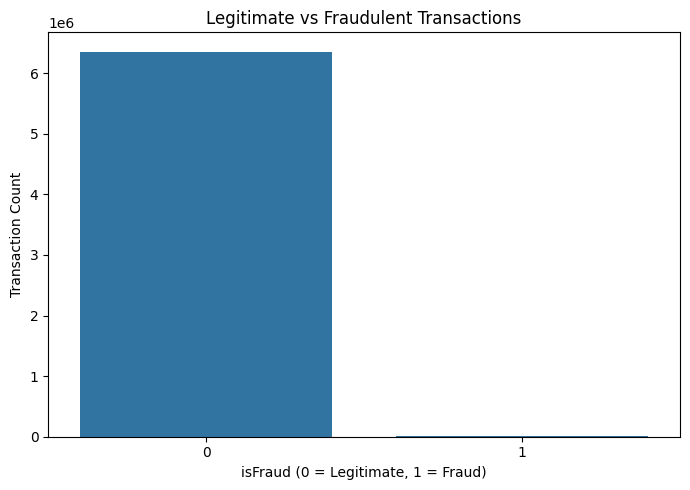

In [3]:

fraud_counts = df["isFraud"].value_counts().sort_index()

fraud_summary = pd.DataFrame({
    "count": fraud_counts,
    "percentage": fraud_counts / len(df) * 100
})

fraud_summary.index = ["Legitimate", "Fraud"]
display(fraud_summary)

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="isFraud")
plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("isFraud (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Count")
plt.tight_layout()
plt.show()


,total_transactions,fraud_transactions,fraud_rate,fraud_rate_percent
type,,,,
TRANSFER,532909,4097,0.007688,0.768799
CASH_OUT,2237500,4116,0.001840,0.183955
CASH_IN,1399284,0,0.000000,0.000000
DEBIT,41432,0,0.000000,0.000000
PAYMENT,2151495,0,0.000000,0.000000


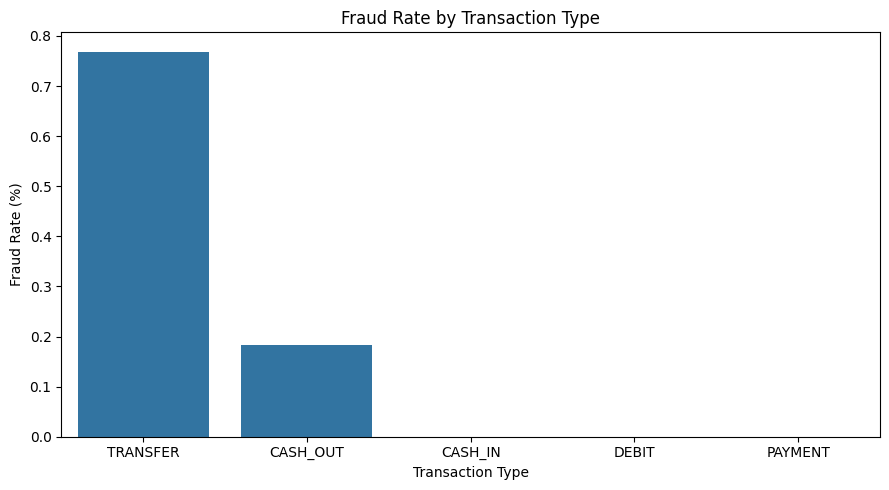

In [4]:
# transaaction type analysis


type_summary = (
    df.groupby("type")["isFraud"]
    .agg(
        total_transactions="count",
        fraud_transactions="sum",
        fraud_rate="mean"
    )
    .sort_values("fraud_rate", ascending=False)
)

type_summary["fraud_rate_percent"] = (
    type_summary["fraud_rate"] * 100
)

display(type_summary)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=type_summary.reset_index(),
    x="type",
    y="fraud_rate_percent"
)
plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Fraud Rate (%)")
plt.tight_layout()
plt.show()


,count,mean,median,min,max
isFraud,,,,,
0,6354407,1.781970e+05,74684.72,0.01,92445516.64
1,8213,1.467967e+06,441423.44,0.00,10000000.00


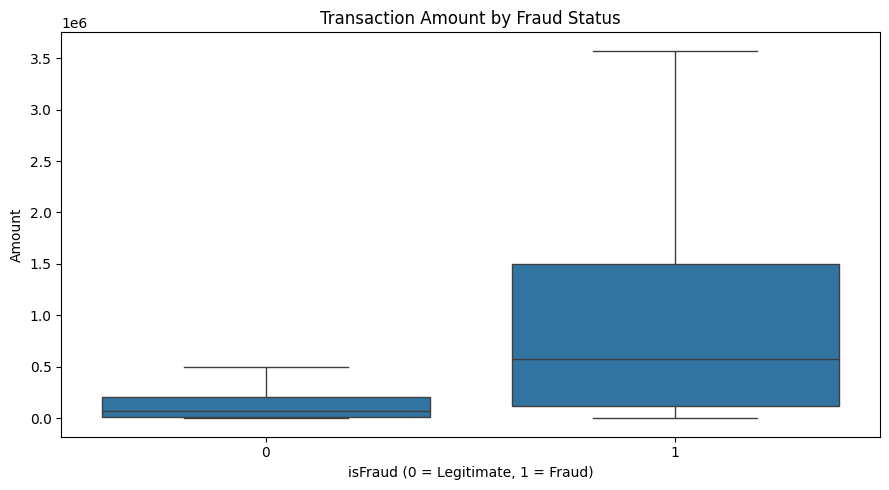

In [5]:
# transaction amount analysis


amount_summary = (
    df.groupby("isFraud")["amount"]
    .agg(["count", "mean", "median", "min", "max"])
)

display(amount_summary)

# Sample only for visualization to reduce plotting time
plot_df = df.sample(
    n=min(100_000, len(df)),
    random_state=42
)

plt.figure(figsize=(9, 5))
sns.boxplot(
    data=plot_df,
    x="isFraud",
    y="amount",
    showfliers=False
)
plt.title("Transaction Amount by Fraud Status")
plt.xlabel("isFraud (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Amount")
plt.tight_layout()
plt.show()


In [6]:

# Compare sender and receiver balance behavior by fraud label

balance_columns = [
    "oldbalanceOrg",
    "newbalanceOrig",
    "oldbalanceDest",
    "newbalanceDest",
]

balance_summary = (
    df.groupby("isFraud")[balance_columns]
    .median()
    .T
)

balance_summary.columns = ["Legitimate", "Fraud"]

display(balance_summary)


,Legitimate,Fraud
oldbalanceOrg,14069.0,438983.45
newbalanceOrig,0.0,0.00
oldbalanceDest,133311.8,0.00
newbalanceDest,214881.7,4676.42


In [7]:

# Calculate balance differences for analysis

df["origin_balance_change"] = (
    df["oldbalanceOrg"] - df["newbalanceOrig"]
)

df["origin_balance_error"] = (
    df["origin_balance_change"] - df["amount"]
)

display(
    df.groupby("isFraud")["origin_balance_error"]
    .agg(["median", "mean", "min", "max"])
)


,median,mean,min,max
isFraud,,,,
0,-69049.31,-201338.558109,-92445516.64,1.000000e-02
1,0.00,-10692.325265,-10000000.00,3.725290e-09


In [8]:

from pathlib import Path

REPORT_DIR = PROJECT_ROOT / "artifacts" / "reports"
PLOT_DIR = PROJECT_ROOT / "artifacts" / "plots"

REPORT_DIR.mkdir(parents=True, exist_ok=True)
PLOT_DIR.mkdir(parents=True, exist_ok=True)

type_summary.to_csv(
    REPORT_DIR / "fraud_rate_by_transaction_type.csv"
)

fraud_summary.to_csv(
    REPORT_DIR / "fraud_class_distribution.csv"
)

print("EDA reports saved successfully.")
print("Reports:", REPORT_DIR)
print("Plots:", PLOT_DIR)


EDA reports saved successfully.
Reports: c:\Users\Greesha Vaishnavi\Desktop\end_to_end_projects\Fraud_Detection_MLOps\artifacts\reports
Plots: c:\Users\Greesha Vaishnavi\Desktop\end_to_end_projects\Fraud_Detection_MLOps\artifacts\plots
